In [1]:
import numpy as np, math, time, random, collections
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tictactoe import (empty_board, actions, result, terminal, utility, other,
                       show_board, random_player as ttt_random, play as ttt_play)

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
plt.rcParams['figure.dpi'] = 90
SEED = 2026
ALL_ROWS = []        # gom kết quả các ván đấu để lập bảng tổng hợp cuối báo cáo

In [2]:
def eval_fun(state, player='x'):
    """Heuristic cho trạng thái. Trả về (giá trị, terminal?)."""
    u = utility(state, player)
    if u is not None:                       # trạng thái kết thúc -> lợi ích thật
        return u, True
    score = 0
    board = np.array(state).reshape((3, 3))
    diagonals = np.array([[board[i][i] for i in range(3)], [board[i][2 - i] for i in range(3)]])
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row == ' '): score += .4
            if sum(row == other(player)) == 2 and any(row == ' '): score -= .4
    return score, False

# kiểm tra nhanh trên 4 bàn cờ mẫu của notebook gốc
b1 = empty_board()
b2 = empty_board(); b2[0] = b2[1] = b2[2] = 'x'
b3 = empty_board(); b3[0] = b3[1] = b3[3] = 'x'; b3[4] = b3[8] = 'o'
b4 = empty_board(); b4[0] = b4[3] = 'x'; b4[1] = b4[4] = 'o'
for name, b in [("rỗng", b1), ("x đã thắng", b2), ("x có 2 đường mở, o có 1", b3), ("x 2 quân dọc, o 2 quân dọc", b4)]:
    print(f"{name:32s} eval cho x = {eval_fun(b)}   eval cho o = {eval_fun(b, 'o')}")

rỗng                             eval cho x = (0, False)   eval cho o = (0, False)
x đã thắng                       eval cho x = (1, True)   eval cho o = (-1, True)
x có 2 đường mở, o có 1          eval cho x = (0.8, False)   eval cho o = (-0.8, False)
x 2 quân dọc, o 2 quân dọc       eval cho x = (0.0, False)   eval cho o = (0.0, False)


In [3]:
COUNT = 0   # số nút đã duyệt trong lần tìm kiếm hiện tại

def alpha_beta_search(board, cutoff=None, player='x'):
    """cutoff=None: Minimax + Alpha-Beta đầy đủ. Trả về dict(move, value, nodes, ms)."""
    global COUNT
    COUNT = 0
    t = time.perf_counter()
    value, move = max_value_ab(board, player, -math.inf, +math.inf, 0, cutoff)
    return {"move": move, "value": value, "nodes": COUNT, "ms": 1000 * (time.perf_counter() - t)}

def max_value_ab(state, player, alpha, beta, depth, cutoff):
    global COUNT
    COUNT += 1
    v, is_terminal = eval_fun(state, player)
    if is_terminal or (cutoff is not None and depth >= cutoff):
        return v, None
    v, move = -math.inf, None
    for a in actions(state):
        v2, _ = min_value_ab(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move
    return v, move

def min_value_ab(state, player, alpha, beta, depth, cutoff):
    global COUNT
    COUNT += 1
    v, is_terminal = eval_fun(state, player)
    if is_terminal or (cutoff is not None and depth >= cutoff):
        return v, None
    v, move = +math.inf, None
    for a in actions(state):
        v2, _ = max_value_ab(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move
    return v, move

def move_values(board, player='x'):
    """Giá trị Minimax THẬT (tìm tới cuối ván) của từng nước đi hợp lệ, theo góc nhìn của `player`.
    Dùng làm 'đáp án chuẩn' để chấm chất lượng nước đi: nước đi tối ưu là nước có giá trị lớn nhất."""
    return {a: min_value_ab(result(board, player, a), player, -math.inf, math.inf, 1, None)[0] for a in actions(board)}

# Hai tác tử của đề + Alpha-Beta đầy đủ
def heuristic2_player(board, player='x'): return alpha_beta_search(board, cutoff=2, player=player)["move"]
def heuristic4_player(board, player='x'): return alpha_beta_search(board, cutoff=4, player=player)["move"]
def alpha_beta_player(board, player='x'): return alpha_beta_search(board, cutoff=None, player=player)["move"]

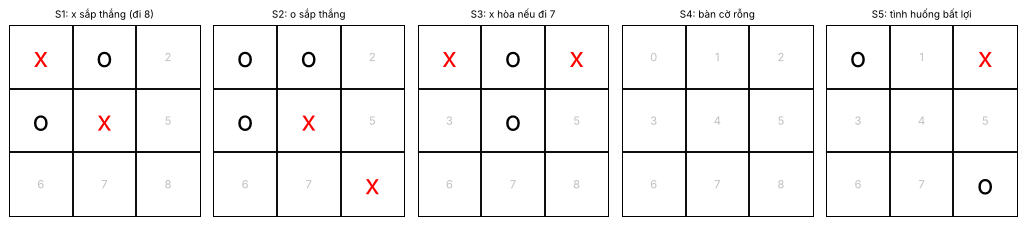

In [4]:
def board_from(x=(), o=()):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b

TEST = {
    "S1: x sắp thắng (đi 8)":   board_from(x=(0, 4), o=(1, 3)),
    "S2: o sắp thắng":          board_from(x=(4, 8), o=(0, 1, 3)),
    "S3: x hòa nếu đi 7":       board_from(x=(0, 2), o=(1, 4)),
    "S4: bàn cờ rỗng":          empty_board(),
    "S5: tình huống bất lợi":   board_from(x=(2,), o=(0, 8)),
}

def draw_boards(boards):
    fig, axes = plt.subplots(1, len(boards), figsize=(2.3 * len(boards), 2.7))
    for ax, (name, b) in zip(np.atleast_1d(axes), boards.items()):
        ax.set_xlim(-.5, 2.5); ax.set_ylim(2.5, -.5); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
        for k in (.5, 1.5): ax.axhline(k, color='k'); ax.axvline(k, color='k')
        for i in range(9):
            r, c = divmod(i, 3); s = b[i]
            ax.text(c, r, s if s != ' ' else str(i), ha='center', va='center',
                    fontsize=22 if s != ' ' else 9, color={'x': 'red', 'o': 'black', ' ': 'silver'}[s])
        ax.set_title(name, fontsize=8)
    plt.tight_layout(); plt.show()

draw_boards(TEST)

In [5]:
def random_positions(n_per_ply=20, plies=(2, 4, 6), seed=SEED):
    rng = np.random.RandomState(seed); out = [empty_board()]
    for p in plies:
        c = 0
        while c < n_per_ply:
            b = empty_board(); pl = 'x'; ok = True
            for _ in range(p):
                if terminal(b): ok = False; break
                b = result(b, pl, rng.choice(actions(b))); pl = other(pl)
            if ok and not terminal(b): out.append(b); c += 1
    return out

POS = random_positions()
TRUE = [move_values(b) for b in POS]
is_opt = lambda i, a: TRUE[i][a] == max(TRUE[i].values())
print(len(POS), "thế cờ kiểm thử")

class Timed:
    """Bọc một tác tử để đo thời gian trung bình mỗi nước đi (ms)."""
    def __init__(self, f): self.f, self.t = f, []
    def __call__(self, board, player='x'):
        t = time.perf_counter(); a = self.f(board, player); self.t.append(time.perf_counter() - t); return a
    @property
    def ms(self): return 1000 * float(np.mean(self.t))

def versus(agent, name, opponent=ttt_random, opp_name="Random", n=100, seed=SEED, group="TTT"):
    """Tác tử đấu n ván khi đi trước và n ván khi đi sau. Trả về DataFrame 2 dòng."""
    out = []
    np.random.seed(seed); random.seed(seed)
    t = Timed(agent); r = ttt_play(t, opponent, N=n)
    out.append({"Tác tử": name, "Đối thủ": opp_name, "Vai": "X (đi trước)", "Số ván": n,
                "Thắng": r['x'], "Hòa": r['d'], "Thua": r['o'], "Thời gian TB/nước (ms)": round(t.ms, 3)})
    np.random.seed(seed + 1); random.seed(seed + 1)
    t = Timed(agent); r = ttt_play(opponent, t, N=n)
    out.append({"Tác tử": name, "Đối thủ": opp_name, "Vai": "O (đi sau)", "Số ván": n,
                "Thắng": r['o'], "Hòa": r['d'], "Thua": r['x'], "Thời gian TB/nước (ms)": round(t.ms, 3)})
    for o in out: ALL_ROWS.append(dict(o, group=group))
    return pd.DataFrame(out)


61 thế cờ kiểm thử


---
# Bài 5 – Pure Monte Carlo Search (PMCS)

**Ý tưởng:** không dùng hàm heuristic thủ công. Với mỗi nước đi hợp lệ, chạy một số ván mô phỏng *ngẫu nhiên đến hết ván* (`playout`) và lấy **lợi ích trung bình**; chọn nước có trung bình cao nhất.
Tổng ngân sách `N` playout được **chia đều** cho các nước đi (`n = ⌊N / số nước⌋` mỗi nước).

* `playout(state, action, player)`: thực hiện `action` rồi chơi ngẫu nhiên đến khi ván kết thúc, trả về lợi ích theo góc nhìn `player`.
* `playouts(board, action, player, N)`: lặp `playout` N lần.
* `pmcs(board, N, player)`: trả về nước đi có lợi ích trung bình lớn nhất.

In [6]:
def playout(state, action, player='x'):
    """Một ván mô phỏng ngẫu nhiên bắt đầu bằng `action`; trả về lợi ích cuối ván theo góc nhìn `player`."""
    state = result(state, player, action)
    current = other(player)
    while True:
        u = utility(state, player)
        if u is not None: return u
        state = result(state, current, np.random.choice(actions(state)))
        current = other(current)

def playouts(board, action, player='x', N=100):
    return [playout(board, action, player) for _ in range(N)]

def pmcs(board, N=100, player='x', return_scores=False):
    """Pure Monte Carlo Search: N playout chia đều cho các nước đi, chọn nước có lợi ích trung bình lớn nhất."""
    acts = actions(board)
    n = max(1, math.floor(N / len(acts)))
    ps = {a: float(np.mean(playouts(board, a, player, N=n))) for a in acts}
    best = max(ps, key=ps.get)
    return (best, ps) if return_scores else best

def pmcs10_player(board, player='x'):   return pmcs(board, N=10, player=player)
def pmcs100_player(board, player='x'):  return pmcs(board, N=100, player=player)
def pmcs1000_player(board, player='x'): return pmcs(board, N=1000, player=player)

# minh họa: lợi ích trung bình của từng nước đầu tiên trên bàn rỗng (N = 5000)
np.random.seed(SEED)
best, ps = pmcs(empty_board(), N=5000, return_scores=True)
print("Bàn rỗng, N=5000 -> nước đi:", best)
print({a: round(v, 2) for a, v in ps.items()})

Bàn rỗng, N=5000 -> nước đi: 4
{0: 0.38, 1: 0.18, 2: 0.38, 3: 0.22, 4: 0.55, 5: 0.17, 6: 0.35, 7: 0.23, 8: 0.38}


**Nhận xét.** Với N = 5000 trên bàn rỗng, PMCS cho nước 4 (ô giữa) có lợi ích trung bình cao nhất (0,55), tiếp theo là các góc 0, 2, 8 (0,38); các ô cạnh thấp nhất (0,17–0,23). Đây đúng với kiến thức về trò chơi nhưng PMCS đạt được mà không cần heuristic nào.

## 5.1 Độ ổn định của nước đi khi N = 10, 100, 1000

Vì PMCS là thuật toán ngẫu nhiên, cùng một thế cờ có thể cho nước đi khác nhau ở mỗi lần chạy. Với mỗi trạng thái kiểm thử và mỗi N, chạy **50 lần** và ghi: nước đi hay gặp nhất, tần suất của nó (càng cao càng ổn định), % lần chọn đúng nước tối ưu, thời gian mỗi lần gọi.

In [7]:
REPEAT = 50
rows = []
for sname, b in TEST.items():
    mv = move_values(b); best = max(mv.values())
    for N in (10, 100, 1000):
        np.random.seed(SEED)
        picks, ts = [], []
        for _ in range(REPEAT):
            t = time.perf_counter(); picks.append(pmcs(b, N=N)); ts.append(time.perf_counter() - t)
        cnt = collections.Counter(picks); modal, f = cnt.most_common(1)[0]
        rows.append({"Trạng thái": sname.split(':')[0], "N": N, "Nước hay gặp nhất": modal,
                     "Tần suất (ổn định)": f"{100 * f / REPEAT:.0f}%",
                     "% lần chọn nước tối ưu": f"{100 * np.mean([mv[p] == best for p in picks]):.0f}%",
                     "Số nước khác nhau": len(cnt), "Thời gian/lần (ms)": round(1000 * np.mean(ts), 2)})
df_stab = pd.DataFrame(rows); display(df_stab)

,Trạng thái,N,Nước hay gặp nhất,Tần suất (ổn định),% lần chọn nước tối ưu,Số nước khác nhau,Thời gian/lần (ms)
0,S1,10,2,62%,82%,5,1.00
1,S1,100,8,94%,100%,3,10.14
2,S1,1000,8,100%,100%,1,90.76
3,S2,10,2,66%,100%,4,0.53
4,S2,100,6,60%,100%,2,7.30
5,S2,1000,6,50%,100%,2,57.98
6,S3,10,3,36%,28%,5,1.41
7,S3,100,7,80%,80%,4,10.16
8,S3,1000,7,100%,100%,1,105.00
9,S4,10,0,56%,100%,6,1.81


**Nhận xét (50 lần lặp mỗi ô).**
* **Càng nhiều playout càng ổn định:** ở S1, S3, S5 nước hay gặp nhất xuất hiện 94 %, 80 %, 90 % với N=100 và **100 %** với N=1000 (N=10: 62 %, 36 %, 32 %). Số nước khác nhau được chọn giảm tương ứng (S3: 5 → 4 → 1).
* **Chất lượng cũng tăng:** ở S3 chỉ **28 %** lần chọn đúng nước 7 với N=10 (mỗi nước chỉ có ⌊10/7⌋ = 1 playout), 80 % với N=100, 100 % với N=1000.
* **Độ ổn định thấp không nhất thiết là xấu:** S2 là thế thua (mọi nước đều giá trị −1) nên nước hay gặp chỉ 50–66 % mà vẫn 100 % "tối ưu". Còn ở bàn rỗng S4 nhiều nước gần ngang nhau (giá trị TB ~0,38 cho các góc), nên N=100 chỉ có 30 % cùng một nước (9 nước khác nhau), N=1000 lên 74 %.
* Thời gian tăng tuyến tính theo N: ~1 ms → ~10 ms → ~91 ms (S1), bàn rỗng đắt nhất (189 ms ở N=1000) vì ván mô phỏng dài hơn.

## 5.2 Chất lượng trên 61 thế cờ ngẫu nhiên (cùng tập với mục 4.5)

In [8]:
rows = []
for N in (10, 100, 1000):
    np.random.seed(SEED); t = time.perf_counter()
    picks = [pmcs(b, N=N) for b in POS]; dt = time.perf_counter() - t
    rows.append({"N": N, "% nước đi tối ưu": round(100 * np.mean([is_opt(i, a) for i, a in enumerate(picks)]), 1),
                 "Thời gian TB/nước (ms)": round(1000 * dt / len(POS), 2)})
df_pq = pd.DataFrame(rows); display(df_pq)

,N,% nước đi tối ưu,Thời gian TB/nước (ms)
0,10,73.8,0.83
1,100,95.1,8.69
2,1000,96.7,95.04


**Nhận xét.** Trên 61 thế cờ: N=10 chỉ chọn nước tối ưu **73,8 %**, N=100 đạt **95,1 %**, N=1000 đạt **96,7 %** (cải thiện nhỏ so với N=100 nhưng thời gian tăng 10 lần: 8,7 → 95,0 ms). PMCS với N=1000 vẫn chưa đạt 100 % như Alpha-Beta cutoff ≥ 5 (mục 4.5), tức là lỗi còn lại không chỉ do phương sai lấy mẫu mà do **chính sách playout ngẫu nhiên** (xem câu thảo luận 4).

In [9]:
df_p = pd.concat([versus(pmcs10_player,   "Pure Monte Carlo (N=10)"),
                  versus(pmcs100_player,  "Pure Monte Carlo (N=100)"),
                  versus(pmcs1000_player, "Pure Monte Carlo (N=1000)")], ignore_index=True)
display(df_p)

df_pp = versus(pmcs100_player, "PMCS N=100", opponent=pmcs10_player, opp_name="PMCS N=10", group="TTT-extra")
display(df_pp)

,Tác tử,Đối thủ,Vai,Số ván,Thắng,Hòa,Thua,Thời gian TB/nước (ms)
0,Pure Monte Carlo (N=10),Random,X (đi trước),100,90,4,6,1.149
1,Pure Monte Carlo (N=10),Random,O (đi sau),100,66,5,29,0.851
2,Pure Monte Carlo (N=100),Random,X (đi trước),100,99,1,0,12.635
3,Pure Monte Carlo (N=100),Random,O (đi sau),100,90,5,5,11.434
4,Pure Monte Carlo (N=1000),Random,X (đi trước),100,98,2,0,125.240
5,Pure Monte Carlo (N=1000),Random,O (đi sau),100,92,7,1,105.122


,Tác tử,Đối thủ,Vai,Số ván,Thắng,Hòa,Thua,Thời gian TB/nước (ms)
0,PMCS N=100,PMCS N=10,X (đi trước),100,91,7,2,12.367
1,PMCS N=100,PMCS N=10,O (đi sau),100,45,20,35,10.293


,Số playout N,Vai,Tỷ lệ thắng,Tỷ lệ hòa,Tỷ lệ thua,Thời gian TB/nước (ms)
0,10,X (đi trước),90%,4%,6%,1.149
1,10,O (đi sau),66%,5%,29%,0.851
2,100,X (đi trước),99%,1%,0%,12.635
3,100,O (đi sau),90%,5%,5%,11.434
4,1000,X (đi trước),98%,2%,0%,125.240
5,1000,O (đi sau),92%,7%,1%,105.122


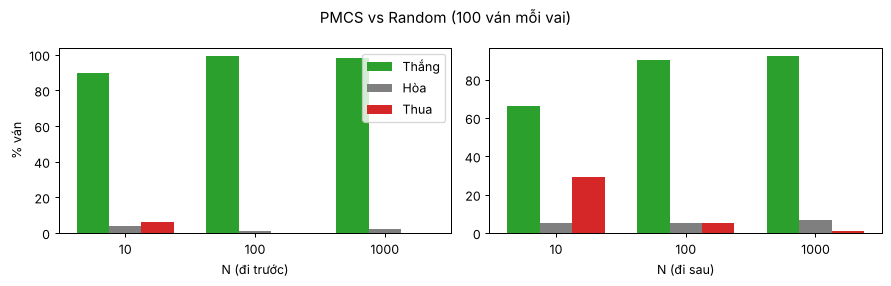

In [10]:
# Bảng đề yêu cầu: tỷ lệ thắng / hòa / thua theo N (tác tử đi trước, 100 ván) + vai đi sau để đối chiếu
tab = []
for N, name in [(10, "Pure Monte Carlo (N=10)"), (100, "Pure Monte Carlo (N=100)"), (1000, "Pure Monte Carlo (N=1000)")]:
    for vai in ("X (đi trước)", "O (đi sau)"):
        r = df_p[(df_p["Tác tử"] == name) & (df_p["Vai"] == vai)].iloc[0]
        tab.append({"Số playout N": N, "Vai": vai, "Tỷ lệ thắng": f"{r['Thắng']}%", "Tỷ lệ hòa": f"{r['Hòa']}%",
                    "Tỷ lệ thua": f"{r['Thua']}%", "Thời gian TB/nước (ms)": r["Thời gian TB/nước (ms)"]})
df_b5 = pd.DataFrame(tab); display(df_b5)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
xs = df_p[df_p["Vai"] == "X (đi trước)"]; xo = df_p[df_p["Vai"] == "O (đi sau)"]
lab = ["10", "100", "1000"]; w = .35; ix = np.arange(3)
for k, (col, c) in enumerate([("Thắng", "tab:green"), ("Hòa", "tab:gray"), ("Thua", "tab:red")]):
    ax[0].bar(ix + (k - 1) * .25, xs[col].values, .25, label=col, color=c)
ax[0].set_xticks(ix); ax[0].set_xticklabels(lab); ax[0].set_xlabel("N (đi trước)"); ax[0].set_ylabel("% ván"); ax[0].legend()
for k, (col, c) in enumerate([("Thắng", "tab:green"), ("Hòa", "tab:gray"), ("Thua", "tab:red")]):
    ax[1].bar(ix + (k - 1) * .25, xo[col].values, .25, label=col, color=c)
ax[1].set_xticks(ix); ax[1].set_xticklabels(lab); ax[1].set_xlabel("N (đi sau)")
plt.suptitle("PMCS vs Random (100 ván mỗi vai)"); plt.tight_layout(); plt.show()